In [1]:
%pip install pandas numpy scipy matplotlib seaborn statsmodels

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest

In [3]:
df = pd.read_csv("ab_test_data_small.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

First 5 rows:
  user_id group  converted
0   A0001     A          0
1   A0002     A          0
2   A0003     A          0
3   A0004     A          0
4   A0005     A          0

Dataset shape: (1000, 3)

Missing values:
user_id      0
group        0
converted    0
dtype: int64


In [4]:
df = df.drop_duplicates(subset="user_id")
df = df.dropna(subset=["user_id", "group", "converted"])

df = df[
    df["group"].isin(["A", "B"])
    & df["converted"].isin([0, 1])
].copy()

print("\nCleaned dataset shape:", df.shape)


Cleaned dataset shape: (1000, 3)


In [5]:
summary = df.groupby("group").agg(
    visitors=("user_id", "nunique"),
    conversions=("converted", "sum"),
    conversion_rate=("converted", "mean")
)

summary["conversion_rate_pct"] = (
    summary["conversion_rate"] * 100
)

print("\nConversion Summary:")
print(summary)



Conversion Summary:
       visitors  conversions  conversion_rate  conversion_rate_pct
group                                                             
A           500           19            0.038                  3.8
B           500           33            0.066                  6.6


In [6]:
rate_a = summary.loc["A", "conversion_rate"]
rate_b = summary.loc["B", "conversion_rate"]

absolute_lift = (rate_b - rate_a) * 100

if rate_a != 0:
    relative_uplift = (
        (rate_b - rate_a) / rate_a
    ) * 100
else:
    relative_uplift = np.nan

print("\nAbsolute Lift:", round(absolute_lift, 2),
      "percentage points")

print("Relative Uplift:", round(relative_uplift, 2), "%")


Absolute Lift: 2.8 percentage points
Relative Uplift: 73.68 %


In [7]:
conversions = np.array([
    summary.loc["A", "conversions"],
    summary.loc["B", "conversions"]
])

visitors = np.array([
    summary.loc["A", "visitors"],
    summary.loc["B", "visitors"]
])

z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=visitors,
    alternative="two-sided"
)

print("\nZ-statistic:", round(z_stat, 4))
print("P-value:", round(p_value, 4))

alpha = 0.05

if p_value < alpha:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")


Z-statistic: -1.994
P-value: 0.0462
Result: Statistically significant difference.


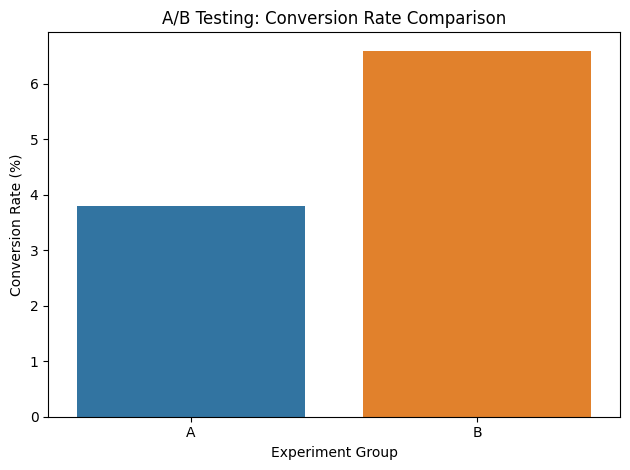

In [8]:
plot_data = summary.reset_index()

sns.barplot(
    data=plot_data,
    x="group",
    y="conversion_rate_pct",
    hue="group",
    legend=False
)

plt.title("A/B Testing: Conversion Rate Comparison")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()

In [9]:
if p_value < alpha and rate_b > rate_a:
    print("\nRecommendation: Version B performed better.")
elif p_value < alpha and rate_a > rate_b:
    print("\nRecommendation: Version A performed better.")
else:
    print("\nRecommendation: No statistically significant winner.")
    print("Consider collecting more data or reviewing the experiment.")


Recommendation: Version B performed better.
